# Tariff front-loading: the data

Five questions. Run top to bottom.

Set your Census key first: `export CK=your_key_here`

In [1]:
import os, json, urllib.request, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
warnings.filterwarnings("ignore")

KEY  = os.environ.get("CK")
BASE = "https://api.census.gov/data/timeseries/intltrade/imports/hs"
RED, GREY = "#C8102E", "#5B6770"
NAMES = {"74":"copper", "76":"aluminum", "40":"rubber", "73":"steel articles"}
print("census key set:", bool(KEY))

census key set: True


## 1. What imports data do we have?

One row for every product group, country and month since 2015.

"Product group" means an HS chapter, the top level of the international product code.
Chapter 74 is copper, 76 is aluminum. There are 98 of them.

In [2]:
p = pd.read_csv("imports_hs2_panel.csv", dtype={"chapter":str, "cty_name":str})
p["date"] = pd.to_datetime(dict(year=p.year, month=p.month, day=1))
p["kg"]   = p.air_kg + p.ves_kg

print(f"rows      {len(p):,}")
print(f"months    {p.date.nunique()}   ({p.date.min():%b %Y} to {p.date.max():%b %Y})")
print(f"products  {p.chapter.nunique()} chapters")
print(f"countries {p.cty_code.nunique()}")
p.head(3)

rows      1,035,855
months    139   (Jan 2015 to Jul 2026)
products  98 chapters
countries 234


,year,month,cty_code,cty_name,chapter,value_usd,air_kg,ves_kg,cnt_kg,date,kg
0,2015,1,4010,SWEDEN,70,824162,3479,62118,62118,2015-01-01,65597
1,2015,1,4039,NORWAY,70,2064,0,86,86,2015-01-01,86
2,2015,1,4050,FINLAND,70,1440699,335,156981,156981,2015-01-01,157316


**One catch worth knowing.** The weight columns only count ships and planes. Nothing that
arrives by truck or train is weighed. That matters for Canada and Mexico, where about half of
aluminum arrives overland. Dollar values are still correct, only the weights are short.

## 2. What does a tariff look like in the data?

Aluminum and copper both got tariffs in 2025. Here is the raw monthly weight.

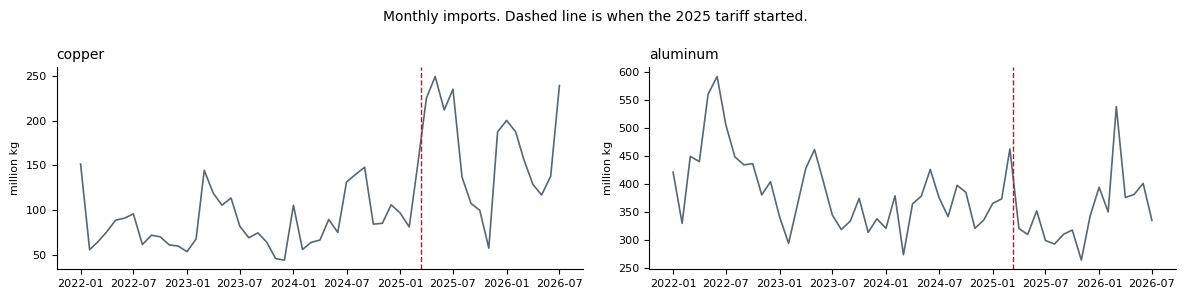

In [3]:
def series(ch):
    return p[p.chapter == ch].groupby("date").kg.sum().sort_index().asfreq("MS")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, ch in zip(axes, ["74", "76"]):
    s = series(ch).loc["2022":] / 1e6
    ax.plot(s.index, s.values, lw=1.2, color=GREY)
    ax.axvline(pd.Timestamp("2025-03-12"), color=RED, ls="--", lw=1)
    ax.set_title(f"{NAMES[ch]}", fontsize=10, loc="left")
    ax.set_ylabel("million kg", fontsize=8)
    ax.tick_params(labelsize=8)
    for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.suptitle("Monthly imports. Dashed line is when the 2025 tariff started.", fontsize=10)
plt.tight_layout(); plt.show()

You can see a bump before the line and a dip after. But imports move around for all sorts of
reasons, so we need to compare against what normally would have happened.

## 3. How do we know what is "normal"?

We fit a model on the years before the tariff, use it to predict what 2025 should have looked
like, and measure the gap. The grey band is the model's normal error, so anything outside it is
unusual.

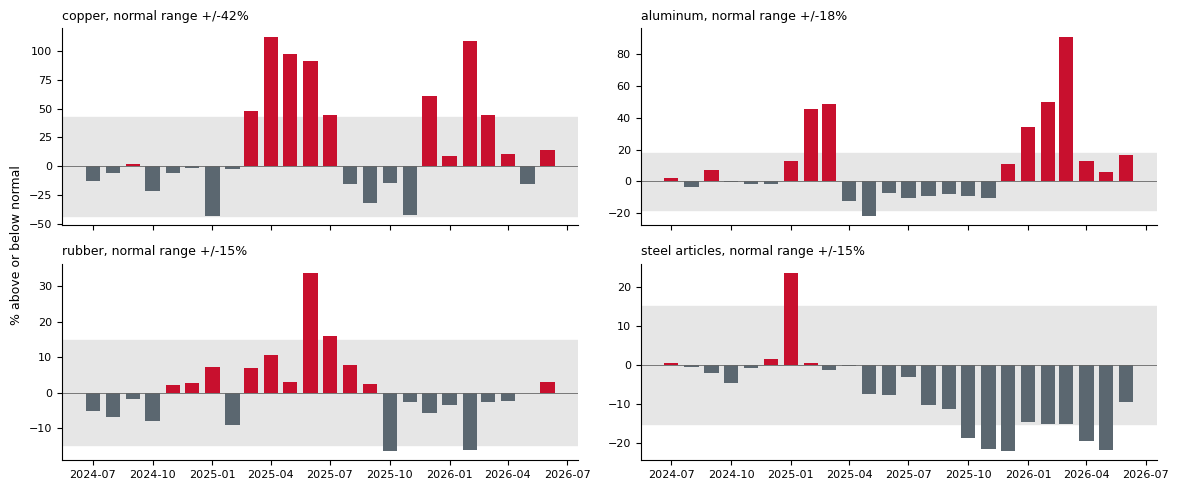

In [4]:
def expected(s, cut="2024-12", window=36):
    """Predict what imports should have been, using only data before the tariff."""
    s = s.replace(0, np.nan).dropna()
    before = s[:cut]
    log_s  = np.log(before)
    parts  = STL(log_s, period=12, robust=True).fit()
    trend, season = parts.trend, parts.seasonal

    # carry the recent trend forward
    t = np.arange(len(trend))
    slope, _ = np.polyfit(t[-window:], trend.values[-window:], 1)
    # average seasonal pattern of the last 3 years
    profile = (pd.DataFrame({"m": season.index.month, "s": season.values})
                 .groupby("m")["s"].apply(lambda x: x.tail(3).mean()))

    steps = np.arange(len(s.index)) - (len(before) - 1)
    pred  = np.exp((trend.values[-1] + slope*steps) + s.index.month.map(profile).values)
    normal_error = np.std(log_s.values - (trend + season).values, ddof=1)
    return pd.Series(pred, index=s.index), 1.96 * normal_error * 100

fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex=True)
for ax, ch in zip(axes.ravel(), NAMES):
    s = series(ch)
    pred, band = expected(s)
    gap = ((s/pred - 1) * 100).loc["2024-07":"2026-06"]
    ax.axhspan(-band, band, color="0.90")
    ax.axhline(0, color="0.4", lw=.6)
    ax.bar(gap.index, gap.values, width=22,
           color=[RED if v > 0 else GREY for v in gap.values])
    ax.set_title(f"{NAMES[ch]}, normal range +/-{band:.0f}%", fontsize=9, loc="left")
    ax.tick_params(labelsize=8)
    for sp in ("top","right"): ax.spines[sp].set_visible(False)
fig.supylabel("% above or below normal", fontsize=9)
plt.tight_layout(); plt.show()

Copper rose 111% above normal, aluminum 49%. Both well outside their normal range, both
followed by months below normal.

**That dip is the question the project is about.** Are they working through what they stocked up
on, or did they simply stop buying?

## 4. Which products did this happen to?

We ran the same comparison on all 98 chapters.

In [5]:
a = pd.read_csv("anomalies_all_chapters.csv", dtype={"chapter":str})
label = {"78":"lead","18":"cocoa","80":"tin","76":"aluminum","74":"copper","05":"animal products",
         "22":"beverages","40":"rubber","25":"stone, cement","75":"nickel","98":"special category",
         "73":"steel articles","71":"precious stones","44":"wood"}
a["name"] = a.chapter.map(label).fillna("")

print(f"{(a.ratio>1).sum()} of {len(a)} product groups rose further above normal than usual in early 2025\n")
top = a.sort_values("ratio", ascending=False).head(10)
print(f"{'':<4}{'product':<18}{'peak':>8}{'normal range':>14}{'when':>9}")
for _, r in top.iterrows():
    print(f"{r.chapter:<4}{r['name']:<18}{r.peak:>+7.0f}%{'+/-'+format(r.band,'.0f')+'%':>14}{r.month:>9}")

31 of 97 product groups rose further above normal than usual in early 2025

    product               peak  normal range     when
78  lead                 +804%        +/-98%   Mar-25
18  cocoa                 +83%        +/-27%   Jun-25
80  tin                   +96%        +/-33%   Jan-25
76  aluminum              +49%        +/-18%   Mar-25
74  copper               +111%        +/-42%   Apr-25
05  animal products       +38%        +/-14%   Jun-25
22  beverages             +31%        +/-13%   Apr-25
40  rubber                +34%        +/-15%   Jun-25
25  stone, cement         +24%        +/-11%   Mar-25
75  nickel                +53%        +/-27%   Apr-25


**Two of these are not tariff stories, and that is important.**

Cocoa is near the top, but cocoa prices moved violently in 2024 and 2025 for supply reasons that
have nothing to do with tariffs.

"Special category" is not a product at all. It is an accounting bucket for things like US goods
coming back after repair.

Right now our method flags anything unusual. It cannot tell a tariff from a bad harvest. Fixing
that is what question 5 is about.

## 5. What tariffs do we have, and what is still missing?

We searched 2,792 government documents and found 134 tariff actions.

In [6]:
e = pd.read_csv("events/tariff_events.csv")
core = e[e.action_kind != "SCOPE_CHANGE"]
print(f"documents searched   2,792")
print(f"tariff actions found   {len(e)}")
print(f"of those, genuinely new actions   {len(core)}")
print(f"(the rest adjust an existing tariff rather than create one)\n")
print(e.authority.value_counts().to_string())

documents searched   2,792
tariff actions found   134
of those, genuinely new actions   66
(the rest adjust an existing tariff rather than create one)

authority
SECTION_232    47
SECTION_301    30
UNKNOWN        28
IEEPA          27
SECTION_201     1
OTHER           1


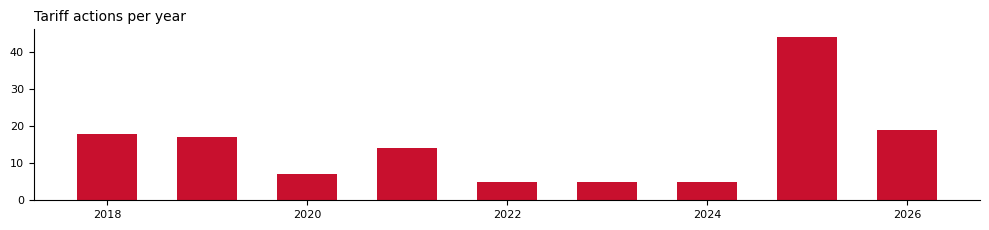

In [7]:
fig, ax = plt.subplots(figsize=(10, 2.4))
e["year"] = pd.to_datetime(e.announcement_date, errors="coerce").dt.year
v = e.dropna(subset=["year"]).year.value_counts().sort_index()
ax.bar(v.index, v.values, color=RED, width=.6)
ax.set_title("Tariff actions per year", fontsize=10, loc="left")
ax.tick_params(labelsize=8)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

### The missing piece

To connect a tariff to the import data we need to know **which products and which countries it
covered**. Right now we do not.

The documents reference the product lists instead of containing them. A tariff notice says the
products are "those listed in U.S. note 20(b)", and that note is published somewhere else.

In [8]:
print("what the product column currently holds:\n")
print(e.hs_chapters.value_counts().head(5).to_string())
print(f"\nrows with no product listed: {e.hs_chapters.isna().sum()} of {len(e)}")
print("\n99 is not a product. It is the code the tariff surcharge itself is filed under.")

what the product column currently holds:

hs_chapters
99                42
98;99              9
76                 2
84                 2
20;22;82;88;99     1

rows with no product listed: 58 of 134

99 is not a product. It is the code the tariff surcharge itself is filed under.


### Update: we got the lists

The US tariff schedule publishes them. We pulled it and matched **488 of 637** tariff codes to the
products or countries they cover.

In [9]:
cov = pd.read_csv("coverage/coverage_final.csv", dtype={"chapter":str})
how = {"ENUMERATED":"lists exact product codes",
       "MATERIAL_CLASS":"names a material, e.g. 'aluminum articles'",
       "COUNTRY_WIDE":"applies to a whole country"}
print("tariffs describe what they cover in three different ways:\n")
for k, g in cov.groupby("mechanism"):
    print(f"  {how[k]:<45} {g.htsno.nunique():>4} codes")
print(f"\nWe needed three different approaches, not one.")

tariffs describe what they cover in three different ways:

  applies to a whole country                     271 codes
  lists exact product codes                      100 codes
  names a material, e.g. 'aluminum articles'     117 codes

We needed three different approaches, not one.


### Does it work yet? Not quite, and we know why.

With the link built we can finally ask: did products with tariffs behave differently from products
without?

The answer so far is **not clearly**. Tariffed months run a little hotter, but not enough to be
sure it is not chance.

The reason is sample size. Only **18 tariffs** both gave companies enough warning to rush anything
and have product lists we can match to our data. Eighteen is too few.

Two things are making it worse, and both are fixable:

**Our matching is too rough.** A typical tariff covers about 5 specific products inside a group
holding hundreds. We mark the whole group as tariffed, so the effect gets averaged away.

**We lump countries together.** A tariff on China is measured against imports from everywhere, so
China's rush competes with every other supplier.

Fixing both means working at a finer product level and keeping countries separate. That is the
next phase.